In [65]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [66]:
path = "/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/olist_clean.parquet"
model_df = pd.read_parquet(path)
model_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,item_count,total_price,...,n_unique_seller_city,n_unique_seller_state,total_payment_value,max_payment_installments,n_unique_payment_types,customer_city,customer_state,delivery_delay,delivery_delay_days,is_delayed
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,29.99,...,1.0,1.0,38.71,3.0,1.0,sao paulo,SP,-8 days +21:25:13,-7.107488,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,118.70,...,1.0,1.0,141.46,1.0,1.0,barreiras,BA,-6 days +15:27:45,-5.355729,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,159.90,...,1.0,1.0,179.12,3.0,1.0,vianopolis,GO,-18 days +18:06:29,-17.245498,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,45.00,...,1.0,1.0,72.20,1.0,1.0,sao goncalo do amarante,RN,-13 days +00:28:42,-12.980069,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,19.90,...,1.0,1.0,28.62,1.0,1.0,santo andre,SP,-10 days +18:17:02,-9.238171,False


In [67]:
candidate_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "average_product_width_cm",
    "item_count",
    "n_unique_products",
    "n_unique_sellers",
    "n_unique_categories",
    "total_payment_value",
    "max_payment_installments",
    "n_unique_payment_types"
]

In [68]:
experimental_df = model_df.dropna(
    subset=candidate_features + ["is_delayed"]
).copy()

In [69]:
print(experimental_df.shape)
print(experimental_df[candidate_features].isna().sum().sum())
print(experimental_df["is_delayed"].value_counts())

(96436, 28)
0
is_delayed
False    88610
True      7826
Name: count, dtype: Int64


In [70]:
X = experimental_df[candidate_features]
y = experimental_df["is_delayed"].astype(int)

print(X.shape)
print(y.shape)

(96436, 13)
(96436,)


In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (77148, 13)
X_test: (19288, 13)
y_train: (77148,)
y_test: (19288,)


In [72]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [73]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

In [74]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9111
Precision: 0.2565
Recall   : 0.0505
F1 Score : 0.0844
ROC-AUC  : 0.6008


In [75]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=candidate_features
).sort_values(ascending=False)

print(feature_importance)

total_payment_value          0.188872
total_freight_value          0.173856
total_price                  0.142617
total_product_weight_g       0.131246
max_payment_installments     0.104391
average_product_height_cm    0.086113
average_product_length_cm    0.082487
average_product_width_cm     0.076572
item_count                   0.005063
n_unique_categories          0.003153
n_unique_payment_types       0.003129
n_unique_products            0.001804
n_unique_sellers             0.000697
dtype: float64


In [76]:

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [77]:
y_pred_balanced = rf_balanced.predict(X_test)
y_prob_balanced = rf_balanced.predict_proba(X_test)[:, 1]

In [78]:
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)
precision_balanced = precision_score(y_test, y_pred_balanced)
recall_balanced = recall_score(y_test, y_pred_balanced)
f1_balanced = f1_score(y_test, y_pred_balanced)
roc_auc_balanced = roc_auc_score(y_test, y_prob_balanced)

print(f"Accuracy : {accuracy_balanced:.4f}")
print(f"Precision: {precision_balanced:.4f}")
print(f"Recall   : {recall_balanced:.4f}")
print(f"F1 Score : {f1_balanced:.4f}")
print(f"ROC-AUC  : {roc_auc_balanced:.4f}")

Accuracy : 0.8967
Precision: 0.1767
Recall   : 0.0748
F1 Score : 0.1051
ROC-AUC  : 0.6062


In [79]:
target_candidates = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g"
]

target_summary = experimental_df[target_candidates].describe().T

target_summary["skewness"] = experimental_df[target_candidates].skew()

print(target_summary)

                          count         mean          std   min     25%  \
total_price             96436.0   137.028749   209.002619  0.85   45.90   
total_freight_value     96436.0    22.783884    21.560037  0.00   13.85   
total_product_weight_g  96436.0  2386.179570  4769.056526  0.00  300.00   

                           50%      75%        max   skewness  
total_price              86.50   149.90   13440.00   9.889548  
total_freight_value      17.17    24.01    1794.96  12.280372  
total_product_weight_g  750.00  2050.00  184400.00   6.575169  


In [80]:
target_corr = experimental_df[candidate_features].corr()

print(target_corr[
    ["total_price",
     "total_freight_value",
     "total_product_weight_g"]
])

                           total_price  total_freight_value  \
total_price                   1.000000             0.411338   
total_freight_value           0.411338             1.000000   
total_product_weight_g        0.349604             0.640119   
average_product_length_cm     0.144310             0.258127   
average_product_height_cm     0.228050             0.334931   
average_product_width_cm      0.169087             0.264692   
item_count                    0.153660             0.439231   
n_unique_products             0.063187             0.197207   
n_unique_sellers              0.042612             0.132516   
n_unique_categories           0.024528             0.076694   
total_payment_value           0.995934             0.491637   
max_payment_installments      0.316162             0.200803   
n_unique_payment_types        0.036219             0.026661   

                           total_product_weight_g  
total_price                              0.349604  
total_freight

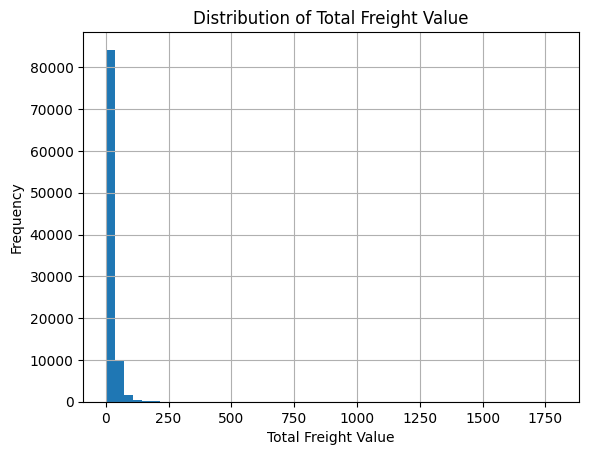

In [81]:
import matplotlib.pyplot as plt

experimental_df["total_freight_value"].hist(bins=50)

plt.xlabel("Total Freight Value")
plt.ylabel("Frequency")
plt.title("Distribution of Total Freight Value")
plt.show()

# feature: distance

In [82]:
new_file = '/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance).parquet'

df = pd.read_parquet(new_file)

In [83]:
print(df.shape)
print(df.columns.tolist())

(99418, 29)
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'item_count', 'total_price', 'total_freight_value', 'n_unique_products', 'n_unique_sellers', 'total_product_weight_g', 'average_product_length_cm', 'average_product_height_cm', 'average_product_width_cm', 'n_unique_categories', 'n_unique_seller_city', 'n_unique_seller_state', 'total_payment_value', 'max_payment_installments', 'n_unique_payment_types', 'customer_city', 'customer_state', 'delivery_delay', 'delivery_delay_days', 'is_delayed', 'average_distance_km']


In [84]:
final_features = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km"
]

In [85]:
df[final_features].isna().sum()

total_price                   775
total_freight_value           775
total_product_weight_g        775
average_product_length_cm     791
average_product_height_cm     791
item_count                    775
max_payment_installments        1
average_distance_km          1264
dtype: int64

In [86]:
model_df = df.dropna(subset=final_features).copy()

print(model_df.shape)

(98137, 29)


In [87]:
X = model_df[final_features].copy()
y = model_df["is_delayed"].copy()

print(X.shape)
print(y.shape)
print(y.value_counts())
print(y.value_counts(normalize=True))

(98137, 8)
(98137,)
is_delayed
False    88184
True      7776
Name: count, dtype: Int64
is_delayed
False    0.918966
True     0.081034
Name: proportion, dtype: Float64


In [88]:
model_df = df.dropna(
    subset=final_features + ["is_delayed"]
).copy()

print(model_df.shape)
print(model_df["is_delayed"].isna().sum())

(95960, 29)
0


In [89]:
X = model_df[final_features].copy()
y = model_df["is_delayed"].copy()

In [90]:
print(X.shape)
print(y.shape)
print(y.value_counts())

(95960, 8)
(95960,)
is_delayed
False    88184
True      7776
Name: count, dtype: Int64


In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(76768, 8)
(19192, 8)


In [92]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.9148082534389329
Precision: 0.16101694915254236
Recall   : 0.012218649517684888
F1       : 0.022713687985654513
ROC-AUC  : 0.5957680497390478


In [94]:
importance = pd.Series(
    model.feature_importances_,
    index=final_features
).sort_values(ascending=False)

print(importance)

average_distance_km          0.229540
total_freight_value          0.169325
total_price                  0.167205
total_product_weight_g       0.142445
average_product_height_cm    0.112309
average_product_length_cm    0.104357
max_payment_installments     0.067569
item_count                   0.007249
dtype: float64


In [95]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression
logreg = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

logreg.fit(X_train_scaled, y_train)

# Prediction
y_pred_logreg = logreg.predict(X_test_scaled)
y_prob_logreg = logreg.predict_proba(X_test_scaled)[:, 1]

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_linea

In [96]:
logreg_results = {
    "Accuracy": accuracy_score(y_test, y_pred_logreg),
    "Precision": precision_score(y_test, y_pred_logreg),
    "Recall": recall_score(y_test, y_pred_logreg),
    "F1": f1_score(y_test, y_pred_logreg),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logreg)
}

logreg_results

{'Accuracy': 0.6484472696957065,
 'Precision': 0.10036945812807882,
 'Recall': 0.4192926045016077,
 'F1': 0.16196745745870078,
 'ROC-AUC': 0.5697639626720135}

In [97]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [98]:
xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb)
}

xgb_results

{'Accuracy': 0.9189245518966236,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0,
 'ROC-AUC': 0.6037760430197625}

In [99]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logreg_results["Accuracy"],
        accuracy_score(y_test, y_pred),
        xgb_results["Accuracy"]
    ],
    "Precision": [
        logreg_results["Precision"],
        precision_score(y_test, y_pred),
        xgb_results["Precision"]
    ],
    "Recall": [
        logreg_results["Recall"],
        recall_score(y_test, y_pred),
        xgb_results["Recall"]
    ],
    "F1": [
        logreg_results["F1"],
        f1_score(y_test, y_pred),
        xgb_results["F1"]
    ],
    "ROC-AUC": [
        logreg_results["ROC-AUC"],
        roc_auc_score(y_test, y_prob),
        xgb_results["ROC-AUC"]
    ]
})

results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.648447,0.100369,0.419293,0.161967,0.569764
1,Random Forest,0.914808,0.161017,0.012219,0.022714,0.595768
2,XGBoost,0.918925,0.000000,0.000000,0.000000,0.603776


In [100]:
results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.6484,0.1004,0.4193,0.1620,0.5698
1,Random Forest,0.9148,0.1610,0.0122,0.0227,0.5958
2,XGBoost,0.9189,0.0000,0.0000,0.0000,0.6038


In [101]:
import pandas as pd

pd.Series(y_prob_xgb).describe()

count    19192.000000
mean         0.080694
std          0.030451
min          0.006725
25%          0.061457
50%          0.075724
75%          0.091977
max          0.506285
dtype: float64

In [102]:
(y_prob_xgb >= 0.5).sum()

np.int64(1)

In [103]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
7,average_distance_km,0.229540
1,total_freight_value,0.169325
0,total_price,0.167205
2,total_product_weight_g,0.142445
4,average_product_height_cm,0.112309
3,average_product_length_cm,0.104357
6,max_payment_installments,0.067569
5,item_count,0.007249


In [104]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

# 1) 置换重要度（在测试集上，用 AUC 打分）
r = permutation_importance(
    model, X_test, y_test,
    scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1
)
print(pd.DataFrame({
    "feature": X_test.columns,
    "auc_drop": r.importances_mean,
    "std": r.importances_std
}).sort_values("auc_drop", ascending=False))

# 2) 去掉 freight 后重训（建议跑 5 个种子取均值）
feats_wo = [f for f in final_features if f != "total_freight_value"]
# 用同样的模型和划分，分别在 final_features 和 feats_wo 上训练，比较 AUC 均值±标准差

                     feature  auc_drop       std
7        average_distance_km  0.047895  0.006469
1        total_freight_value  0.039002  0.005930
0                total_price  0.036695  0.005874
2     total_product_weight_g  0.025578  0.003864
3  average_product_length_cm  0.020365  0.005137
4  average_product_height_cm  0.014899  0.004717
6   max_payment_installments  0.004752  0.003344
5                 item_count  0.004232  0.001563
